In [92]:
import random
import math
import matplotlib.pyplot as plt

# ---------- Параметры ----------
DIM = 10                # размерность задачи
POP_SIZE = 100          # размер популяции
GENERATIONS = 20000       # число поколений
CROSSOVER_RATE = 0.9    # вероятность кроссовера
MUTATION_RATE = 0.8     # вероятность мутации одного гена
MUTATION_SIGMA = 0.8    # сила гауссовой мутации
ALPHA = 0.5             # параметр BLX-alpha
BOUNDS = (-5.12, 5.12)  # границы поиска
TOURNAMENT_K = 3

random.seed(42)         # воспроизводимость

In [73]:
def fitness(x):
    return 10 * len(x) + sum(xi**2 - 10 * math.cos(2 * math.pi * xi) for xi in x)

In [74]:
def create_individual():
    lo, hi = BOUNDS
    return [random.uniform(lo, hi) for _ in range(DIM)]

def create_population():
    return [create_individual() for _ in range(POP_SIZE)]

In [75]:
def tournament_selection(population, fitnesses, k=TOURNAMENT_K):
    idx = random.sample(range(len(population)), k)
    best = min(idx, key=lambda i: fitnesses[i])
    return population[best]

In [87]:
def mutate(individual):
    lo, hi = BOUNDS
    return [
        min(max(g + random.gauss(0, MUTATION_SIGMA), lo), hi)
        if random.random() < MUTATION_RATE else g
        for g in individual
    ]

In [77]:
def crossover(p1, p2):
    if random.random() >= CROSSOVER_RATE:
        return p1[:], p2[:]
    lo, hi = BOUNDS
    c1, c2 = [], []
    for a, b in zip(p1, p2):
        cmin, cmax = min(a, b), max(a, b)
        d = cmax - cmin
        low  = cmin - ALPHA * d
        high = cmax + ALPHA * d
        g1 = random.uniform(low, high)
        g2 = random.uniform(low, high)
        c1.append(min(max(g1, lo), hi))
        c2.append(min(max(g2, lo), hi))
    return c1, c2

In [90]:
def genetic_algorithm():
    population = create_population()
    history = []
    best_x, best_f = None, float("inf")

    for gen in range(GENERATIONS):
        fitnesses = [fitness(ind) for ind in population]

        i_best = min(range(POP_SIZE), key=lambda i: fitnesses[i])
        if fitnesses[i_best] < best_f:
            best_f = fitnesses[i_best]
            best_x = population[i_best][:]

        history.append(best_f)

        if gen % 50 == 0 or gen == GENERATIONS - 1:
            print(f"Поколение {gen:4d} |x* = {best_x}| gen_best = {fitnesses[i_best]:.6f} "
                  f"| global_best = {best_f:.6f}")

        # Элитизм: 2 лучших без изменений
        sorted_idx = sorted(range(POP_SIZE), key=lambda i: fitnesses[i])
        new_population = [population[i][:] for i in sorted_idx[:2]]

        while len(new_population) < POP_SIZE:
            p1 = tournament_selection(population, fitnesses)
            p2 = tournament_selection(population, fitnesses)
            c1, c2 = crossover(p1, p2)
            new_population.append(mutate(c1))
            if len(new_population) < POP_SIZE:
                new_population.append(mutate(c2))

        population = new_population

    return best_x, best_f, history

In [93]:
x, f, history = genetic_algorithm()

print("\n=== Результат ===")
print(f"best f(x) = {f:.8f}")
print(f"||x||     = {math.sqrt(sum(v*v for v in x)):.6f}")
print(f"x = [{', '.join(f'{v:+.4f}' for v in x)}]")

Поколение    0 |x* = [2.2502836532628496, -2.044699973516655, -1.9529250589833906, -0.9380566157392192, -0.9994200365288997, -2.0924907261343026, -3.8165729376342714, -0.8146295421654193, 4.509323988277074, 1.8157357595927852]| gen_best = 109.366882 | global_best = 109.366882
Поколение   50 |x* = [0.07387734555095193, 0.041787347682388454, 1.883929247325904, 0.1859411363038491, 1.0684574917204372, -0.2781043796731044, 1.0764998775207577, -0.8681797397877213, 0.7331448558518522, -0.036280511958865835]| gen_best = 45.643365 | global_best = 45.643365
Поколение  100 |x* = [-1.055371497940456, 0.16200756569846836, -2.197444452933757, -0.8386373995468202, 1.9065862874415505, 0.8804578515928333, -2.0829516072886163, -1.1039497778301233, -0.0064440097875922975, -0.009706653507310259]| gen_best = 41.236437 | global_best = 41.236437
Поколение  150 |x* = [-1.055371497940456, 0.16200756569846836, -2.197444452933757, -0.8386373995468202, 1.9065862874415505, 0.8804578515928333, -2.0829516072886163, 

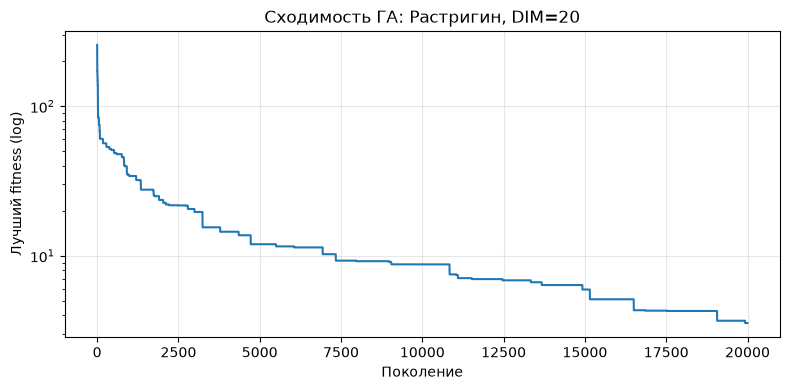

In [80]:
plt.figure(figsize=(8, 4))
plt.plot(history)
plt.yscale("log")
plt.xlabel("Поколение")
plt.ylabel("Лучший fitness (log)")
plt.title(f"Сходимость ГА: Растригин, DIM={DIM}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()